In [1]:
%pip install -q earthengine-api geemap

Note: you may need to restart the kernel to use updated packages.


In [11]:
%pip install -q sgp4 global-land-mask

Note: you may need to restart the kernel to use updated packages.


In [3]:
import ee
from IPython.display import Image
ee.Initialize(project="featuremappingdataset")

pt = ee.Geometry.Point(-122.4, 47.6)
img = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
       .filterBounds(pt)
       .filterDate("2024-06-01", "2024-08-31")
       .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 10))
       .median())

url = img.getThumbURL({"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000,
                       "region": pt.buffer(50000).bounds(), "dimensions": 800})
Image(url=url)

In [12]:
from datetime import datetime, timedelta, timezone
import math, json, os
import numpy as np, pandas as pd

PROJECT = "featuremappingdataset"
OUT_DIR = "dataset"
W, H = 2064, 1544                            # camera sensor pixels (Sony IMX252)
LENSES = {"FOUND": 245, "LOST": 92}          # metres per pixel at ~420 km
SEASONS = {"jun-aug": ("2024-06-01", "2024-09-01"), "dec-feb": ("2023-12-01", "2024-03-01")}
N_PER_CLASS = {"land": 20, "coast": 20, "ocean": 10}
SIM_DAYS = 7          # days of orbit to pick capture points from
SEED = 0
MIN_SUN_ELEV = 10     # only daylight capture points
MIN_SPACING_KM = 600  # keeps frames from overlapping

In [13]:
from sgp4.api import Satrec, WGS72, jday
from global_land_mask import globe

EPOCH = datetime(2026, 10, 28, 11, 12, 28, tzinfo=timezone.utc)
ELEMENTS = dict(inc=51.6335, raan=0.5562, ecc=0.0007038, argp=319.9799,
                ma=40.0670, revs_per_day=15.49088092, bstar=0.10526e-3)

def build_satellite():
    e = ELEMENTS
    sat = Satrec()
    days = (EPOCH - datetime(1949, 12, 31, tzinfo=timezone.utc)).total_seconds() / 86400
    sat.sgp4init(WGS72, "i", 25544, days, e["bstar"], 0.0, 0.0, e["ecc"],
                 math.radians(e["argp"]), math.radians(e["inc"]), math.radians(e["ma"]),
                 e["revs_per_day"] * 2 * math.pi / 1440, math.radians(e["raan"]))
    return sat

def propagate(start, hours, step_s):
    times = [start + timedelta(seconds=s) for s in range(0, int(hours * 3600) + 1, step_s)]
    jf = np.array([jday(t.year, t.month, t.day, t.hour, t.minute, t.second) for t in times])
    jd, fr = np.ascontiguousarray(jf[:, 0]), np.ascontiguousarray(jf[:, 1])
    err, r, _ = build_satellite().sgp4_array(jd, fr)
    tt = (jd + fr - 2451545.0) / 36525
    th = np.radians(((67310.54841 + (876600 * 3600 + 8640184.812866) * tt) % 86400) / 240)
    x = r[:, 0] * np.cos(th) + r[:, 1] * np.sin(th)
    y = -r[:, 0] * np.sin(th) + r[:, 1] * np.cos(th)
    lat = np.degrees(np.arctan2(r[:, 2], np.hypot(x, y)))
    lon = np.degrees(np.arctan2(y, x))
    return pd.DataFrame({"time": times, "lat": lat, "lon": lon})

def sun_elevation(lat, lon, times):
    doy = np.array([t.timetuple().tm_yday for t in times])
    hr = np.array([t.hour + t.minute / 60 + t.second / 3600 for t in times])
    g = 2 * np.pi / 365 * (doy - 1 + (hr - 12) / 24)
    decl = (0.006918 - 0.399912 * np.cos(g) + 0.070257 * np.sin(g) - 0.006758 * np.cos(2 * g)
            + 0.000907 * np.sin(2 * g) - 0.002697 * np.cos(3 * g) + 0.00148 * np.sin(3 * g))
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g) - 0.032077 * np.sin(g)
                    - 0.014615 * np.cos(2 * g) - 0.040849 * np.sin(2 * g))
    ha = np.radians((hr * 60 + eqt + 4 * lon) / 4 - 180)
    phi = np.radians(lat)
    cz = np.sin(phi) * np.sin(decl) + np.cos(phi) * np.cos(decl) * np.cos(ha)
    return 90 - np.degrees(np.arccos(np.clip(cz, -1, 1)))

def land_fraction(lat, lon, width_km, height_km, nx=11, ny=9):
    xs = np.linspace(-width_km / 2, width_km / 2, nx)
    ys = np.linspace(-height_km / 2, height_km / 2, ny)
    la = lat[:, None, None] + ys[None, :, None] / 111.32
    lo = lon[:, None, None] + xs[None, None, :] / (111.32 * np.cos(np.radians(lat))[:, None, None])
    la = np.clip(la, -89.9, 89.9)
    lo = (lo + 180) % 360 - 180
    return globe.is_land(la, lo).mean(axis=(1, 2))

def km_between(lat1, lon1, lat2, lon2):
    p1, p2, dl = np.radians(lat1), np.radians(lat2), np.radians(lon2 - lon1)
    c = np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl)
    return 6371 * np.arccos(np.clip(c, -1, 1))

track = propagate(EPOCH, SIM_DAYS * 24, 60)
track["sun_elev"] = sun_elevation(track.lat.values, track.lon.values, track.time)
big = LENSES["FOUND"] * W / 1000, LENSES["FOUND"] * H / 1000
track["land_frac"] = land_fraction(track.lat.values, track.lon.values, *big)
track["class_guess"] = np.select([track.land_frac < 0.02, track.land_frac > 0.9], ["ocean", "land"], "coast")
day = track[track.sun_elev >= MIN_SUN_ELEV]

picked = []
for cls, n in N_PER_CLASS.items():
    cand = day[day.class_guess == cls].sample(frac=1, random_state=SEED)
    chosen = []
    for row in cand.itertuples():
        if all(km_between(row.lat, row.lon, o.lat, o.lon) >= MIN_SPACING_KM for o in picked + chosen):
            chosen.append(row)
        if len(chosen) == n:
            break
    picked += chosen
    print(f"{cls}: {len(chosen)} points")
points = pd.DataFrame(picked).drop(columns="Index").reset_index(drop=True)
points.insert(0, "point_id", [f"p{i:03d}" for i in range(len(points))])
points

land: 20 points
coast: 20 points
ocean: 10 points


,point_id,time,lat,lon,sun_elev,land_frac,class_guess
0,p000,2026-11-02 11:10:28+00:00,3.988383,-56.714281,22.998430,1.000000,land
1,p001,2026-11-02 21:02:28+00:00,-37.539746,-61.487860,18.090283,0.919192,land
2,p002,2026-11-02 21:00:28+00:00,-42.084838,-69.158723,24.474807,1.000000,land
3,p003,2026-10-29 07:58:28+00:00,24.005430,-1.670806,22.280589,1.000000,land
4,p004,2026-10-29 06:30:28+00:00,9.616008,33.637288,40.157516,1.000000,land
5,p005,2026-11-03 12:02:28+00:00,-13.281233,-61.921161,34.630168,1.000000,land
6,p006,2026-11-02 06:29:28+00:00,10.990800,9.009948,16.555877,1.000000,land
7,p007,2026-11-04 11:12:28+00:00,-3.110124,-63.461908,18.894820,1.000000,land
8,p008,2026-11-02 23:45:28+00:00,-30.805743,142.776981,52.687828,1.000000,land
9,p009,2026-11-04 04:59:28+00:00,1.238026,27.877788,15.898949,1.000000,land


In [14]:
import ee
ee.Initialize(project=PROJECT)

S2 = "COPERNICUS/S2_SR_HARMONIZED"
MODIS = "MODIS/061/MOD09A1"   # fills open ocean, which Sentinel-2 doesn't image

def utm_epsg(lat, lon):
    zone = int((lon + 180) // 6) + 1
    return (32600 if lat >= 0 else 32700) + zone

def frame_image(region, start, end):
    """Seasonal cloud-masked composite: RGB (uint8) + SCL labels + Sentinel-2 coverage flag."""
    col = (ee.ImageCollection(S2).filterBounds(region).filterDate(start, end)
           .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40)))
    def clear(img):
        scl = img.select("SCL")
        ok = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
        return img.updateMask(ok)
    s2 = col.map(clear).select(["B4", "B3", "B2"]).median()
    modis = (ee.ImageCollection(MODIS).filterDate(start, end)
             .select(["sur_refl_b01", "sur_refl_b04", "sur_refl_b03"], ["B4", "B3", "B2"]).median())
    rgb = s2.unmask(modis).visualize(bands=["B4", "B3", "B2"], min=0, max=3000)
    scl = col.select("SCL").mode().unmask(0).toUint8().rename("SCL")
    covered = s2.select("B4").mask().gt(0).unmask(0).toUint8().rename("s2")
    return rgb.addBands(scl).addBands(covered)

def fetch(image, lat, lon, gsd, tiles=1):
    """Pixels on the camera grid, optionally requested as tiles x tiles pieces."""
    epsg = utm_epsg(lat, lon)
    cx, cy = ee.Geometry.Point([lon, lat]).transform(f"EPSG:{epsg}", 1).coordinates().getInfo()
    x0, y0 = cx - W / 2 * gsd, cy + H / 2 * gsd
    rows = []
    for r in np.array_split(np.arange(H), tiles):
        row = []
        for c in np.array_split(np.arange(W), tiles):
            row.append(ee.data.computePixels({
                "expression": image, "fileFormat": "NUMPY_NDARRAY",
                "grid": {"dimensions": {"width": len(c), "height": len(r)},
                         "affineTransform": {"scaleX": gsd, "shearX": 0, "translateX": x0 + c[0] * gsd,
                                             "shearY": 0, "scaleY": -gsd, "translateY": y0 - r[0] * gsd},
                         "crsCode": f"EPSG:{epsg}"}}))
        rows.append(np.concatenate(row, axis=1))
    return np.concatenate(rows, axis=0), epsg, [gsd, 0, x0, 0, -gsd, y0]

def fetch_retry(image, lat, lon, gsd):
    """Whole frame first; if Earth Engine runs out of memory, split into 2x2 then 4x4 tiles."""
    for tiles in (1, 2, 4):
        try:
            return fetch(image, lat, lon, gsd, tiles)
        except ee.EEException as e:
            msg = str(e).lower()
            if "memory" not in msg and "timed out" not in msg:
                raise
            print(f"      too large as {tiles}x{tiles}, retrying in smaller tiles")
    raise RuntimeError("still too large after splitting into 4x4 tiles")

print("Earth Engine ready")

Earth Engine ready


In [15]:
from PIL import Image

LAND_CLASSES = [2, 4, 5, 7, 11]      # dark area, vegetation, bare, unclassified, snow
CLOUD_CLASSES = [3, 8, 9, 10]        # cloud shadow, medium/high cloud, cirrus

def labels(scl):
    n = scl.size
    covered = scl > 0                         # 0 = no Sentinel-2 data (open ocean)
    land = np.isin(scl, LAND_CLASSES)
    water = (scl == 6) | ~covered
    clear = land.sum() + water.sum()
    land_share = land.sum() / clear if clear else 0.0
    out = {"s2_coverage": covered.mean(), "land_frac": land.sum() / n, "water_frac": water.sum() / n,
           "cloud_frac": np.isin(scl, CLOUD_CLASSES).sum() / n, "snow_frac": (scl == 11).sum() / n,
           "land_share_clear": land_share}
    out["class"] = "ocean" if land_share < 0.02 else "land" if land_share > 0.9 else "coast"
    return {k: (round(float(v), 4) if not isinstance(v, str) else v) for k, v in out.items()}

def save_frame(arr, meta):
    folder = os.path.join(OUT_DIR, meta["lens"])
    os.makedirs(folder, exist_ok=True)
    base = os.path.join(folder, f"{meta['point_id']}_{meta['season']}")
    rgb = np.dstack([arr["vis-red"], arr["vis-green"], arr["vis-blue"]]).astype(np.uint8)
    Image.fromarray(rgb).save(base + "_rgb.png")
    Image.fromarray(arr["SCL"].astype(np.uint8)).save(base + "_scl.png")
    with open(base + ".json", "w") as f:
        json.dump(meta, f, indent=2, default=str)

In [19]:
from concurrent.futures import ThreadPoolExecutor, as_completed
from glob import glob

jobs = [(p, lens, gsd, season, start, end)
        for p in points.itertuples() for lens, gsd in LENSES.items()
        for season, (start, end) in SEASONS.items()]
todo = [j for j in jobs
        if not os.path.exists(os.path.join(OUT_DIR, j[1], f"{j[0].point_id}_{j[3]}.json"))]
print(f"{len(jobs) - len(todo)} frames already saved, {len(todo)} to fetch")

def run(job):
    p, lens, gsd, season, start, end = job
    region = ee.Geometry.Point([p.lon, p.lat]).buffer(gsd * W * 0.75).bounds()
    arr, epsg, transform = fetch_retry(frame_image(region, start, end), p.lat, p.lon, gsd)
    meta = {"point_id": p.point_id, "lens": lens, "season": season, "gsd_m": gsd,
            "width": W, "height": H, "center_lat": p.lat, "center_lon": p.lon,
            "capture_time": p.time, "sun_elev": round(float(p.sun_elev), 1),
            "epsg": epsg, "transform": transform, **labels(arr["SCL"])}
    save_frame(arr, meta)
    return meta

with ThreadPoolExecutor(max_workers=4) as pool:
    futures = {pool.submit(run, j): j for j in todo}
    for i, f in enumerate(as_completed(futures), 1):
        p, lens, _, season, _, _ = futures[f]
        try:
            m = f.result()
            print(f"[{i}/{len(todo)}] {p.point_id} {lens} {season}: {m['class']}, "
                  f"land {m['land_share_clear']:.0%}, cloud {m['cloud_frac']:.0%}")
        except Exception as e:
            print(f"[{i}/{len(todo)}] {p.point_id} {lens} {season}: FAILED - {e}")

# re-label every saved frame with the current rules and rebuild the index
rows = []
for path in sorted(glob(os.path.join(OUT_DIR, "*", "*.json"))):
    meta = json.load(open(path))
    meta.update(labels(np.array(Image.open(path.replace(".json", "_scl.png")))))
    json.dump(meta, open(path, "w"), indent=2, default=str)
    rows.append(meta)
pd.DataFrame(rows).to_csv(os.path.join(OUT_DIR, "index.csv"), index=False)
print(f"\nSaved {len(rows)} frames")
print(pd.DataFrame(rows).groupby(["lens", "class"]).size().unstack(fill_value=0))

151 frames already saved, 49 to fetch
[1/49] p012 LOST jun-aug: FAILED - Image.unmask: If one image has no bands, the other must also have no bands. Got 0 and 1.
[2/49] p038 LOST dec-feb: coast, land 87%, cloud 1%
[3/49] p039 FOUND jun-aug: coast, land 74%, cloud 16%
[4/49] p038 FOUND jun-aug: coast, land 41%, cloud 0%
[5/49] p039 LOST jun-aug: land, land 94%, cloud 20%
[6/49] p039 FOUND dec-feb: coast, land 70%, cloud 15%
[7/49] p039 LOST dec-feb: coast, land 75%, cloud 15%
[8/49] p040 FOUND jun-aug: ocean, land 0%, cloud 0%
[9/49] p040 LOST jun-aug: FAILED - Image.unmask: If one image has no bands, the other must also have no bands. Got 0 and 1.
[10/49] p040 LOST dec-feb: FAILED - Image.unmask: Incompatible number of bands in the value image: 3. Expected 0 or 1.
[11/49] p041 FOUND jun-aug: FAILED - Image.unmask: Incompatible number of bands in the value image: 3. Expected 0 or 1.
[12/49] p041 FOUND dec-feb: FAILED - Image.unmask: If one image has no bands, the other must also have no

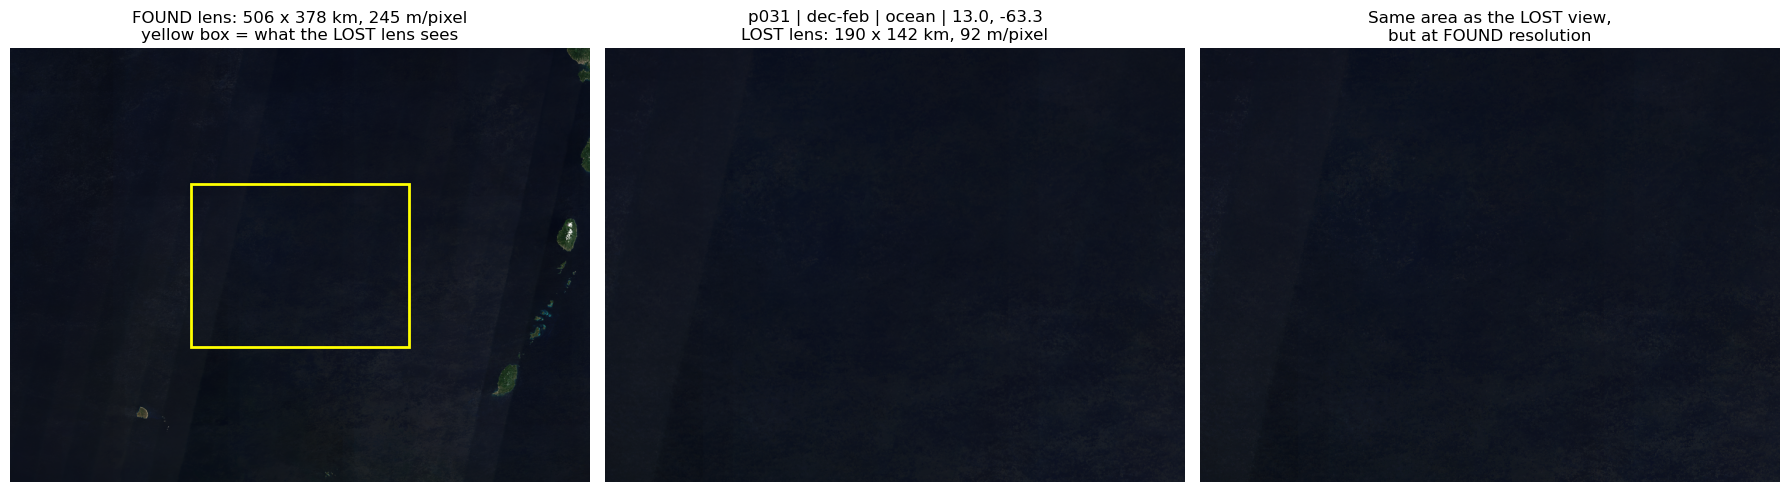

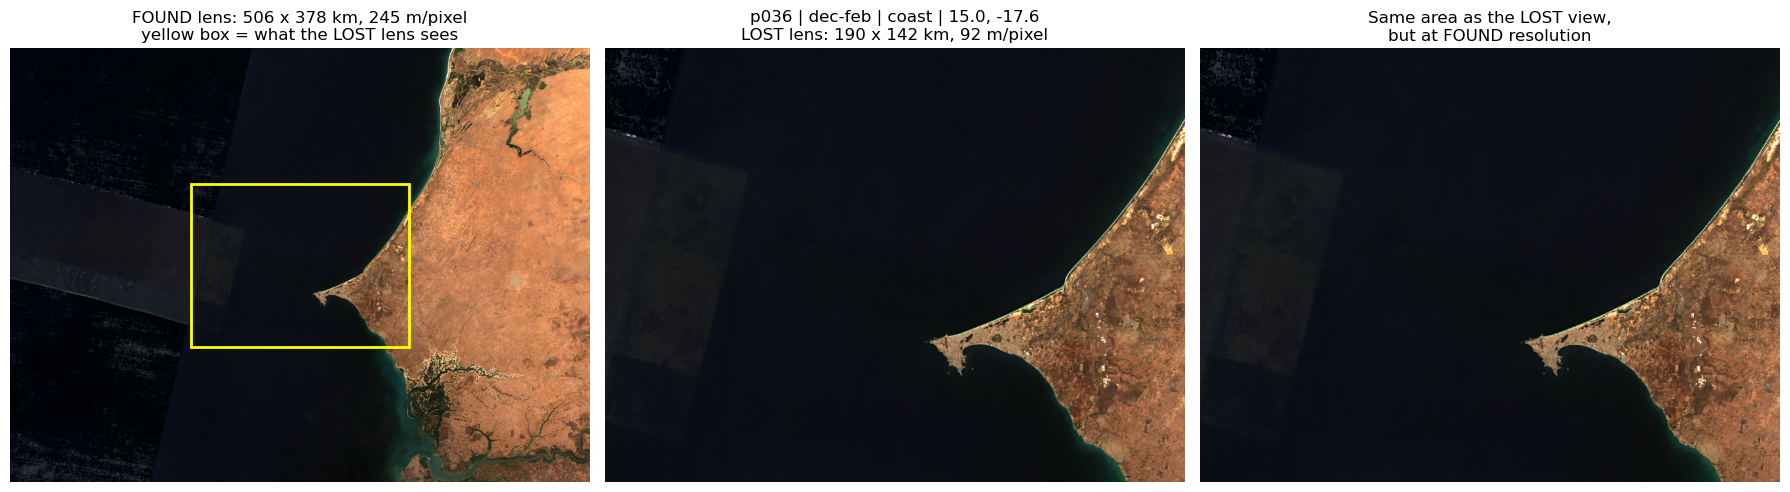

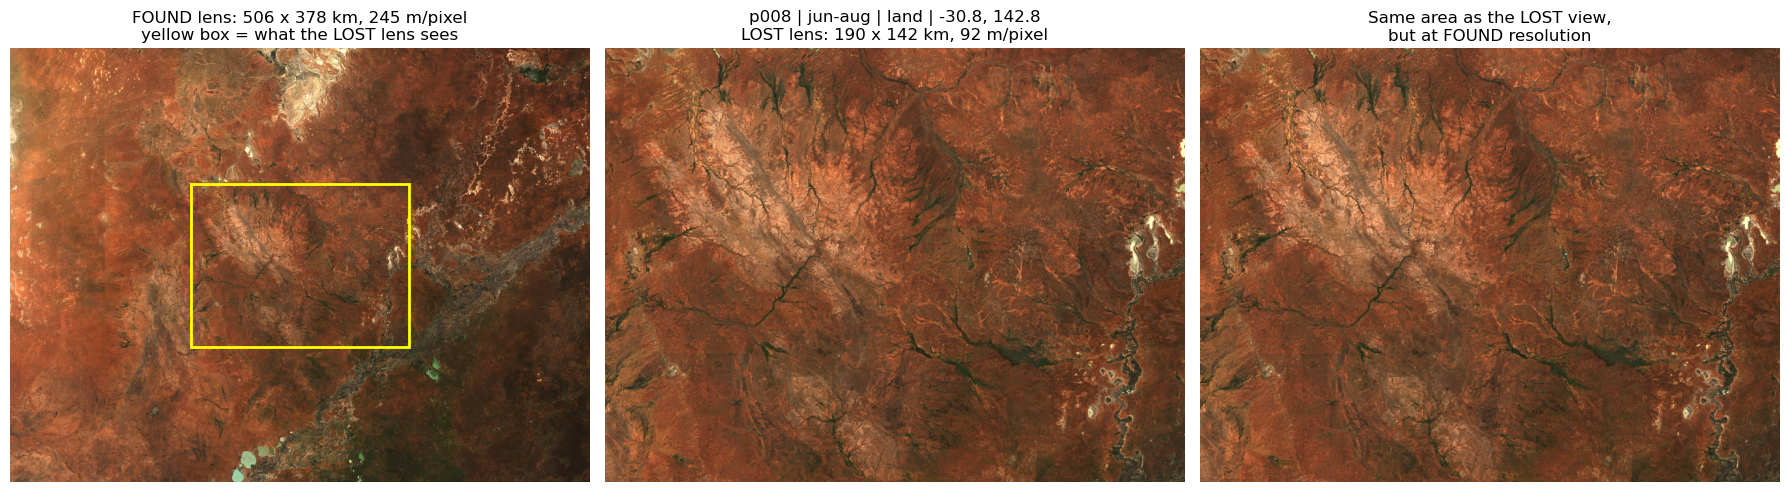

In [20]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
from glob import glob

metas = [json.load(open(p)) for p in glob(os.path.join(OUT_DIR, "*", "*.json"))]
df = pd.DataFrame(metas)
both = df.groupby(["point_id", "season"]).filter(lambda g: {"FOUND", "LOST"} <= set(g.lens))
pairs = both.drop_duplicates(["point_id", "season"]).head(3)   # change 3 to show more
if pairs.empty:
    print("No point has both lenses downloaded yet - let cell 6 run a bit longer.")

def load(lens, pid, season):
    return np.array(Image.open(os.path.join(OUT_DIR, lens, f"{pid}_{season}_rgb.png")))

ratio = LENSES["LOST"] / LENSES["FOUND"]        # LOST view as a fraction of the FOUND view
w, h = W * ratio, H * ratio
x0, y0 = int((W - w) / 2), int((H - h) / 2)

for _, r in pairs.iterrows():
    found, lost = load("FOUND", r.point_id, r.season), load("LOST", r.point_id, r.season)
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))
    ax[0].imshow(found)
    ax[0].add_patch(patches.Rectangle((x0, y0), w, h, fill=False, ec="yellow", lw=2))
    ax[0].set_title(f"FOUND lens: {W*LENSES['FOUND']/1000:.0f} x {H*LENSES['FOUND']/1000:.0f} km, "
                    f"{LENSES['FOUND']} m/pixel\nyellow box = what the LOST lens sees")
    ax[1].imshow(lost)
    ax[1].set_title(f"LOST lens: {W*LENSES['LOST']/1000:.0f} x {H*LENSES['LOST']/1000:.0f} km, "
                    f"{LENSES['LOST']} m/pixel")
    ax[2].imshow(found[y0:y0 + int(h), x0:x0 + int(w)])
    ax[2].set_title("Same area as the LOST view,\nbut at FOUND resolution")
    for a in ax:
        a.axis("off")
    fig.suptitle(f"{r.point_id} | {r.season} | {r['class']} | "
                 f"{r.center_lat:.1f}, {r.center_lon:.1f}", fontsize=12)
    plt.tight_layout(); plt.show()

In [26]:
import cv2, time
from glob import glob

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
gray = lambda img: clahe.apply(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY))
ROT_DEG, SHIFT_PX = 5, (40, 25)   # simulated pose difference between stored map and new photo
RATIO, PX_TOL = 0.8, 3.0          # Lowe ratio test; pixel tolerance for a "correct" match

def load(lens, pid, season):
    base = os.path.join(OUT_DIR, lens, f"{pid}_{season}")
    return np.array(Image.open(base + "_rgb.png").convert("RGB")), np.array(Image.open(base + "_scl.png"))

def valid_mask(scl):
    """Only where Sentinel-2 has real data, kept away from the seams."""
    return cv2.erode(((scl > 0) * 255).astype(np.uint8), np.ones((15, 15), np.uint8))

metas = pd.DataFrame([json.load(open(p)) for p in glob(os.path.join(OUT_DIR, "*", "*.json"))])
pairs = (metas.groupby(["lens", "point_id"]).filter(lambda g: {"jun-aug", "dec-feb"} <= set(g.season))
              .query("season == 'jun-aug'").rename(columns={"class": "cls"}))
print(len(pairs), "location/lens pairs with both seasons")

Hm = cv2.getRotationMatrix2D((W / 2, H / 2), ROT_DEG, 1.0)
Hm[:, 2] += SHIFT_PX
H_true = np.vstack([Hm, [0, 0, 1]])
centre = np.array([[[W / 2, H / 2]]], dtype=np.float64)
truth = cv2.perspectiveTransform(centre, np.linalg.inv(H_true))   # where the photo centre really is on the map

sift = cv2.SIFT_create(nfeatures=4000)
rows = []
for r in pairs.itertuples(index=False):
    ref, ref_scl = load(r.lens, r.point_id, "jun-aug")      # stored reference map (summer)
    test, test_scl = load(r.lens, r.point_id, "jun-aug")   # was "dec-feb"    # new "photo" (winter), shifted + rotated
    test = cv2.warpPerspective(test, H_true, (W, H))
    test_mask = cv2.warpPerspective(valid_mask(test_scl), H_true, (W, H), flags=cv2.INTER_NEAREST)

    t0 = time.perf_counter()
    kr, dr = sift.detectAndCompute(gray(ref), valid_mask(ref_scl))
    kt, dt = sift.detectAndCompute(gray(test), test_mask)
    out = {"lens": r.lens, "point_id": r.point_id, "class": r.cls, "kp_ref": len(kr), "kp_photo": len(kt),
           "matches": 0, "correct": 0, "inliers": 0, "error_km": np.nan, "success": False}
    if dr is not None and dt is not None and len(kr) > 1 and len(kt) > 1:
        good = [m for m, *n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(dr, dt, k=2)
                if n and m.distance < RATIO * n[0].distance]
        pr = np.float32([kr[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        pt = np.float32([kt[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        out["matches"] = len(good)
        if len(good):
            err = np.linalg.norm(cv2.perspectiveTransform(pr.astype(np.float64), H_true) - pt, axis=2).ravel()
            out["correct"] = int((err < PX_TOL).sum())
        if len(good) >= 4:
            H_est, inl = cv2.findHomography(pr, pt, cv2.RANSAC, PX_TOL)
            if H_est is not None:
                est = cv2.perspectiveTransform(centre, np.linalg.inv(H_est))   # where SIFT thinks the centre is
                out["inliers"] = int(inl.sum())
                out["error_km"] = float(np.linalg.norm(est - truth) * r.gsd_m / 1000)
                out["success"] = bool(out["inliers"] >= 8 and out["error_km"] < 5 * r.gsd_m / 1000)
    out["time_s"] = round(time.perf_counter() - t0, 2)
    rows.append(out)

sift_results = pd.DataFrame(rows)
print(sift_results.groupby(["lens", "class"]).agg(
    frames=("success", "size"), success_rate=("success", "mean"),
    median_error_km=("error_km", "median"), median_correct_matches=("correct", "median"),
    median_time_s=("time_s", "median")).round(2))
sift_results.sort_values(["lens", "class"])

85 location/lens pairs with both seasons
             frames  success_rate  median_error_km  median_correct_matches  \
lens  class                                                                  
FOUND coast      17          1.00             0.01                  2056.0   
      land       19          1.00             0.01                  2294.0   
      ocean       8          0.62             0.02                   433.5   
LOST  coast       5          1.00             0.00                  2416.0   
      land       22          1.00             0.00                  2394.0   
      ocean      14          0.79             0.00                   588.0   

             median_time_s  
lens  class                 
FOUND coast           0.39  
      land            0.42  
      ocean           0.32  
LOST  coast           0.40  
      land            0.45  
      ocean           0.34  


,lens,point_id,class,kp_ref,kp_photo,matches,correct,inliers,error_km,success,time_s
42,FOUND,p039,coast,3816,3786,2065,2058,2058,0.010820,True,0.42
45,FOUND,p038,coast,4001,3997,2476,2458,2458,0.008041,True,0.42
46,FOUND,p032,coast,3798,3851,2154,2127,2127,0.006732,True,0.39
47,FOUND,p035,coast,4000,3995,1938,1913,1913,0.007463,True,0.37
49,FOUND,p027,coast,2925,3285,1673,1659,1659,0.024656,True,0.37
...,...,...,...,...,...,...,...,...,...,...,...
29,LOST,p030,ocean,4,15,2,2,0,NaN,False,0.36
31,LOST,p022,ocean,1667,2096,1022,1017,1017,0.002768,True,0.36
34,LOST,p046,ocean,315,300,141,139,139,0.690118,False,0.31
38,LOST,p028,ocean,663,812,447,438,438,0.212907,True,0.29


In [36]:
   fails = sift_results[(sift_results["class"] == "land") & ~sift_results.success]
   for r in fails.itertuples():
       a, _ = load(r.lens, r.point_id, "jun-aug"); b, _ = load(r.lens, r.point_id, "dec-feb")
       fig, ax = plt.subplots(1, 2, figsize=(12, 4))
       ax[0].imshow(a); ax[0].set_title(f"{r.lens} {r.point_id} summer"); ax[1].imshow(b); ax[1].set_title("winter")
       for x in ax: x.axis("off")
       plt.show()

In [29]:
#superpoint+lightglue
%pip install -q torch "git+https://github.com/cvg/LightGlue.git"

Note: you may need to restart the kernel to use updated packages.


In [30]:
import cv2, time
from glob import glob

TEST_SEASON = "dec-feb"          # "jun-aug" = same-season control
ROT_DEG, SHIFT_PX = 5, (40, 25)  # simulated pose difference between map and photo
PX_TOL = 3.0
CAMERA_EFFECTS = True            # blur, vignetting, noise, JPEG on the "photo" only

def load(lens, pid, season):
    base = os.path.join(OUT_DIR, lens, f"{pid}_{season}")
    return np.array(Image.open(base + "_rgb.png").convert("RGB")), np.array(Image.open(base + "_scl.png"))

def valid_mask(scl):
    return cv2.erode(((scl > 0) * 255).astype(np.uint8), np.ones((15, 15), np.uint8))

def camera_effects(img, seed=0):
    """Placeholder camera model until we have real numbers: lens blur, darker corners, noise, JPEG."""
    h, w = img.shape[:2]
    out = cv2.GaussianBlur(img.astype(np.float32), (0, 0), 0.8)
    yy, xx = np.mgrid[0:h, 0:w]
    out *= (1 - 0.3 * (((xx - w / 2) ** 2 + (yy - h / 2) ** 2) / ((w / 2) ** 2 + (h / 2) ** 2)))[..., None]
    out += np.random.default_rng(seed).normal(0, 3, out.shape)
    out = np.clip(out, 0, 255).astype(np.uint8)
    _, enc = cv2.imencode(".jpg", cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 85])
    return cv2.cvtColor(cv2.imdecode(enc, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)

# ---------- matchers: each returns matched points (map pixels, photo pixels) ----------
sift = cv2.SIFT_create(nfeatures=4000)

def match_sift(ref, ref_mask, photo, photo_mask):
    kr, dr = sift.detectAndCompute(cv2.cvtColor(ref, cv2.COLOR_RGB2GRAY), ref_mask)
    kp, dp = sift.detectAndCompute(cv2.cvtColor(photo, cv2.COLOR_RGB2GRAY), photo_mask)
    if dr is None or dp is None or len(kr) < 2 or len(kp) < 2:
        return np.empty((0, 2)), np.empty((0, 2))
    good = [m for m, *n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(dr, dp, k=2)
            if n and m.distance < 0.8 * n[0].distance]
    return (np.float32([kr[m.queryIdx].pt for m in good]).reshape(-1, 2),
            np.float32([kp[m.trainIdx].pt for m in good]).reshape(-1, 2))

_sp = {}
def match_superpoint(ref, ref_mask, photo, photo_mask):
    import torch
    from lightglue import LightGlue, SuperPoint
    from lightglue.utils import numpy_image_to_torch, rbd
    if not _sp:
        _sp["dev"] = "cuda" if torch.cuda.is_available() else "cpu"
        _sp["ext"] = SuperPoint(max_num_keypoints=2048).eval().to(_sp["dev"])
        _sp["lg"] = LightGlue(features="superpoint").eval().to(_sp["dev"])
    dev = _sp["dev"]
    def feats(img, mask):
        with torch.no_grad():
            f = _sp["ext"].extract(numpy_image_to_torch(img).to(dev))   # keypoints come back in full-image pixels
        kp = f["keypoints"][0].cpu().numpy()
        keep = mask[np.clip(kp[:, 1].astype(int), 0, mask.shape[0] - 1),
                    np.clip(kp[:, 0].astype(int), 0, mask.shape[1] - 1)] > 0
        idx = torch.from_numpy(np.flatnonzero(keep)).to(dev)
        for k in ("keypoints", "keypoint_scores", "descriptors"):
            f[k] = f[k][:, idx]
        return f
    fr, fp = feats(ref, ref_mask), feats(photo, photo_mask)
    if fr["keypoints"].shape[1] < 2 or fp["keypoints"].shape[1] < 2:
        return np.empty((0, 2)), np.empty((0, 2))
    with torch.no_grad():
        m = rbd(_sp["lg"]({"image0": fr, "image1": fp}))["matches"].cpu().numpy()
    return (fr["keypoints"][0].cpu().numpy()[m[:, 0]], fp["keypoints"][0].cpu().numpy()[m[:, 1]])

# ---------- shared test harness ----------
metas = pd.DataFrame([json.load(open(p)) for p in glob(os.path.join(OUT_DIR, "*", "*.json"))])
pairs = (metas.groupby(["lens", "point_id"]).filter(lambda g: {"jun-aug", TEST_SEASON} <= set(g.season))
              .query("season == 'jun-aug'").rename(columns={"class": "cls"}))
Hm = cv2.getRotationMatrix2D((W / 2, H / 2), ROT_DEG, 1.0)
Hm[:, 2] += SHIFT_PX
H_true = np.vstack([Hm, [0, 0, 1]])
centre = np.array([[[W / 2, H / 2]]], dtype=np.float64)
truth = cv2.perspectiveTransform(centre, np.linalg.inv(H_true))

def evaluate(name, match_fn):
    rows = []
    for i, r in enumerate(pairs.itertuples(index=False)):
        ref, ref_scl = load(r.lens, r.point_id, "jun-aug")
        photo, photo_scl = load(r.lens, r.point_id, TEST_SEASON)
        if CAMERA_EFFECTS:
            photo = camera_effects(photo, seed=i)
        photo = cv2.warpPerspective(photo, H_true, (W, H))
        photo_mask = cv2.warpPerspective(valid_mask(photo_scl), H_true, (W, H), flags=cv2.INTER_NEAREST)
        t0 = time.perf_counter()
        pr, pp = match_fn(ref, valid_mask(ref_scl), photo, photo_mask)
        out = {"method": name, "lens": r.lens, "point_id": r.point_id, "class": r.cls,
               "matches": len(pr), "correct": 0, "inliers": 0, "error_km": np.nan, "success": False}
        if len(pr):
            err = np.linalg.norm(cv2.perspectiveTransform(pr.reshape(-1, 1, 2).astype(np.float64), H_true)
                                 .reshape(-1, 2) - pp, axis=1)
            out["correct"] = int((err < PX_TOL).sum())
        if len(pr) >= 4:
            H_est, inl = cv2.findHomography(pr, pp, cv2.RANSAC, PX_TOL)
            if H_est is not None:
                est = cv2.perspectiveTransform(centre, np.linalg.inv(H_est))
                out["inliers"] = int(inl.sum())
                out["error_km"] = float(np.linalg.norm(est - truth) * r.gsd_m / 1000)
                out["success"] = bool(out["inliers"] >= 8 and out["error_km"] < 5 * r.gsd_m / 1000)
        out["time_s"] = round(time.perf_counter() - t0, 2)
        rows.append(out)
    return pd.DataFrame(rows)

results = []
for name, fn in [("SIFT", match_sift), ("SuperPoint+LightGlue", match_superpoint)]:
    try:
        results.append(evaluate(name, fn))
        print(name, "done")
    except ImportError as e:
        print(f"{name} skipped (not installed): {e}")
results = pd.concat(results, ignore_index=True)
summary = (results[results["class"] != "ocean"]
           .groupby(["lens", "class", "method"])
           .agg(frames=("success", "size"), success_rate=("success", "mean"),
                median_correct_matches=("correct", "median"), median_time_s=("time_s", "median"))
           .round(2))
summary

SIFT done
Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to /Users/prika/.cache/torch/hub/checkpoints/superpoint_v1.pth


100%|██████████████████████████████████████| 4.96M/4.96M [00:01<00:00, 4.39MB/s]


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /Users/prika/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth


100%|██████████████████████████████████████| 45.3M/45.3M [00:03<00:00, 12.1MB/s]


SuperPoint+LightGlue done


frames  success_rate  \
lens  class method                                       
FOUND coast SIFT                      17          0.94   
            SuperPoint+LightGlue      17          0.76   
      land  SIFT                      19          0.79   
            SuperPoint+LightGlue      19          0.95   
LOST  coast SIFT                       5          1.00   
            SuperPoint+LightGlue       5          1.00   
      land  SIFT                      22          0.73   
            SuperPoint+LightGlue      22          0.86   

                                  median_correct_matches  median_time_s  
lens  class method                                                       
FOUND coast SIFT                                   103.0           0.36  
            SuperPoint+LightGlue                   221.0           5.98  
      land  SIFT                                   108.0           0.39  
            SuperPoint+LightGlue                   482.0           5.98  
LOST  coast SIFT                                   284.0           0.40  
            SuperPoint+LightGlue                   408.0           6.20  
      land  SIFT                                    39.0           0.42  
            SuperPoint+LightGlue                   310.0           6.50

In [31]:
ALT_KM = 420
ATTITUDE_ERR_DEG = 0.1      # placeholder - ask LOST/ADCS how accurate attitude will be

att_km = ALT_KM * np.tan(np.radians(ATTITUDE_ERR_DEG))
results["rough_position_error_km"] = np.sqrt(results["error_km"] ** 2 + att_km ** 2)

print(f"Attitude error of {ATTITUDE_ERR_DEG} deg adds about {att_km:.2f} km\n")
print(results[results.success & (results["class"] != "ocean")]
      .groupby(["lens", "method"])
      .agg(frames=("success", "size"),
           median_alignment_km=("error_km", "median"),
           median_rough_position_km=("rough_position_error_km", "median"))
      .round(2))
print("\nSuccess rate (fraction of frames that found the right location):")
print(results[results["class"] != "ocean"].groupby(["lens", "method"]).success.mean().round(2))

Attitude error of 0.1 deg adds about 0.73 km

                            frames  median_alignment_km  \
lens  method                                              
FOUND SIFT                      31                 0.08   
      SuperPoint+LightGlue      31                 0.15   
LOST  SIFT                      21                 0.01   
      SuperPoint+LightGlue      24                 0.06   

                            median_rough_position_km  
lens  method                                          
FOUND SIFT                                      0.74  
      SuperPoint+LightGlue                      0.75  
LOST  SIFT                                      0.73  
      SuperPoint+LightGlue                      0.74  

Success rate (fraction of frames that found the right location):
lens   method              
FOUND  SIFT                    0.86
       SuperPoint+LightGlue    0.86
LOST   SIFT                    0.78
       SuperPoint+LightGlue    0.89
Name: success, dtype: float64


In [32]:
import numpy as np, cv2, pandas as pd
from scipy.optimize import least_squares

R_EARTH, ALT = 6371.0, 420.0
W, H, PIX_MM = 2064, 1544, 3.45e-3
CAMERAS = {"FOUND": 5.9, "LOST": 15.7}     # focal length, mm

def nadir_frame(lat, lon):
    """Camera axes for a straight-down camera: x = east (right), y = south (down), z = toward Earth."""
    la, lo = np.radians(lat), np.radians(lon)
    up = np.array([np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)])
    east = np.array([-np.sin(lo), np.cos(lo), 0.0])
    north = np.cross(up, east)
    return np.vstack([east, -north, -up]), up

def rot(axis, deg):
    return cv2.Rodrigues(np.asarray(axis, float) / np.linalg.norm(axis) * np.radians(deg))[0]

def project(P, S, Rc, f):
    """Pinhole camera: 3D ground points P (km) seen from satellite S -> pixel coordinates."""
    pc = (P - S) @ Rc.T
    return np.c_[f * pc[:, 0] / pc[:, 2] + W / 2, f * pc[:, 1] / pc[:, 2] + H / 2]

def landmarks(S, Rc, f, n, rng):
    """Random pixels -> rays -> where they hit the Earth (landmarks in view)."""
    px = np.c_[rng.uniform(0, W, n), rng.uniform(0, H, n)]
    d = np.c_[(px[:, 0] - W / 2) / f, (px[:, 1] - H / 2) / f, np.ones(n)] @ Rc
    d /= np.linalg.norm(d, axis=1, keepdims=True)
    b = d @ S
    t = -b - np.sqrt(b ** 2 - (S @ S - R_EARTH ** 2))
    return S + t[:, None] * d

def solve_known_attitude(P, uv, Rc_assumed, f, S0):
    return least_squares(lambda S: (project(P, S, Rc_assumed, f) - uv).ravel(), S0).x

def solve_pnp(P, uv, f):
    c = P.mean(axis=0)                                   # centre coordinates for numerical stability
    K = np.array([[f, 0, W / 2], [0, f, H / 2], [0, 0, 1]])
    obj, img = (P - c).astype(np.float64), uv.astype(np.float64)
    _, rv, tv = cv2.solvePnP(obj, img, K, None, flags=cv2.SOLVEPNP_EPNP)
    _, rv, tv = cv2.solvePnP(obj, img, K, None, rv, tv, True, cv2.SOLVEPNP_ITERATIVE)
    return c - cv2.Rodrigues(rv)[0].T @ tv.ravel()

def run(lat=30.0, lon=10.0, n_landmarks=20, pixel_noise=1.0, trials=50,
        att_errors=(0, 0.01, 0.05, 0.1, 0.5, 1.0), seed=0):
    rng = np.random.default_rng(seed)
    Rc, up = nadir_frame(lat, lon)
    S = (R_EARTH + ALT) * up
    rows = []
    for cam, f_mm in CAMERAS.items():
        f = f_mm / PIX_MM
        for att in att_errors:
            e_known, e_pnp = [], []
            for _ in range(trials):
                P = landmarks(S, Rc, f, n_landmarks, rng)
                uv = project(P, S, Rc, f) + rng.normal(0, pixel_noise, (n_landmarks, 2))
                Rc_assumed = rot(rng.normal(size=3), att) @ Rc      # what the satellite *thinks* its pointing is
                S0 = S + rng.normal(0, 20, 3)                        # starting guess ~20 km off
                e_known.append(np.linalg.norm(solve_known_attitude(P, uv, Rc_assumed, f, S0) - S))
                e_pnp.append(np.linalg.norm(solve_pnp(P, uv, f) - S))
            rows.append({"camera": cam, "attitude_error_deg": att,
                         "known_attitude_km": np.median(e_known),
                         "solve_attitude_too_km": np.median(e_pnp)})
    return pd.DataFrame(rows).round(2)

run()

,camera,attitude_error_deg,known_attitude_km,solve_attitude_too_km
0,FOUND,0.00,0.11,0.66
1,FOUND,0.01,0.15,0.73
2,FOUND,0.05,0.34,0.60
3,FOUND,0.10,0.67,0.65
4,FOUND,0.50,3.29,0.66
5,FOUND,1.00,6.82,0.59
6,LOST,0.00,0.10,1.57
7,LOST,0.01,0.11,1.32
8,LOST,0.05,0.36,1.68
9,LOST,0.10,0.71,1.16


In [35]:
MAP_SEASON, PHOTO_SEASON = "jun-aug", "dec-feb"
MIN_INLIERS = 30      # need a strong match, not a handful of coincidences
MIN_RATIO = 2.0       # the best map must beat the runner-up by at least 2x
PRIOR_KM = None       # None = search the whole database (cold start); e.g. 1500 = only maps within 1500 km of the truth
sift_s = cv2.SIFT_create(nfeatures=2000)

def features(img, mask):
    kp, des = sift_s.detectAndCompute(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), mask)
    pts = np.float32([k.pt for k in kp]) if kp else np.empty((0, 2), np.float32)
    return pts, des

def match_count(fa, fb):
    """Consistent matches under a realistic transform: shift + rotation (< 15 deg) + scale ~1."""
    (pa, da), (pb, db) = fa, fb
    if da is None or db is None or len(pa) < 2 or len(pb) < 2:
        return 0, None
    good = [m for m, *n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(da, db, k=2)
            if n and m.distance < 0.8 * n[0].distance]
    if len(good) < 4:
        return 0, None
    A = pa[[m.queryIdx for m in good]]
    B = pb[[m.trainIdx for m in good]]
    M, inl = cv2.estimateAffinePartial2D(A, B, method=cv2.RANSAC, ransacReprojThreshold=3.0)
    if M is None:
        return 0, None
    scale = np.hypot(M[0, 0], M[1, 0])
    angle = np.degrees(np.arctan2(M[1, 0], M[0, 0]))
    if not (0.9 < scale < 1.1 and abs(angle) < 15):
        return 0, None                      # not a transform a nadir camera could produce
    return int(inl.sum()), np.vstack([M, [0, 0, 1]])

def km_between(lat1, lon1, lat2, lon2):
    p1, p2, dl = np.radians(lat1), np.radians(lat2), np.radians(lon2 - lon1)
    return 6371 * np.arccos(np.clip(np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl), -1, 1))

info = metas.drop_duplicates(["lens", "point_id"]).set_index(["lens", "point_id"])
centre = np.array([[[W / 2, H / 2]]], np.float64)
truth = cv2.perspectiveTransform(centre, np.linalg.inv(H_true)).ravel()   # true photo centre on its own map
search_rows = []
for lens in sorted(metas.lens.unique()):
    have = metas[metas.lens == lens].groupby("point_id").season.apply(set)
    ids = [p for p, s in have.items() if {MAP_SEASON, PHOTO_SEASON} <= s]

    # 1. the database: features from every stored map (computed once)
    database = {}
    for pid in ids:
        img, scl = load(lens, pid, MAP_SEASON)
        database[pid] = features(img, valid_mask(scl))
    print(f"{lens}: database of {len(database)} maps, searching {len(ids)} photos...")

    # 2. each photo is searched against the database; the truth is only used at the end
    for i, pid in enumerate(ids):
        img, scl = load(lens, pid, PHOTO_SEASON)
        img = camera_effects(img, seed=i) if CAMERA_EFFECTS else img
        photo = cv2.warpPerspective(img, H_true, (W, H))
        pmask = cv2.warpPerspective(valid_mask(scl), H_true, (W, H), flags=cv2.INTER_NEAREST)
        fp = features(photo, pmask)

        candidates = list(database)
        if PRIOR_KM is not None:          # simulate the orbit prediction: only search nearby maps
            lat0, lon0 = info.loc[(lens, pid), "center_lat"], info.loc[(lens, pid), "center_lon"]
            candidates = [m for m in candidates
                          if km_between(lat0, lon0, info.loc[(lens, m), "center_lat"],
                                        info.loc[(lens, m), "center_lon"]) <= PRIOR_KM]
        scores = {m: match_count(database[m], fp) for m in candidates}
        ranked = sorted(scores, key=lambda m: scores[m][0], reverse=True)
        best, runner = ranked[0], (ranked[1] if len(ranked) > 1 else None)
        best_inl, best_T = scores[best]
        runner_inl = scores[runner][0] if runner else 0

        if best_inl < MIN_INLIERS or best_inl < MIN_RATIO * max(runner_inl, 1):
            outcome, err_km = "no fix", np.nan
        else:
            gsd_km = info.loc[(lens, best), "gsd_m"] / 1000
            if best == pid:   # right map: how far off is the photo centre?
                est = cv2.perspectiveTransform(centre, np.linalg.inv(best_T)).ravel()
                err_km = float(np.linalg.norm(est - truth) * gsd_km)
            else:             # wrong map: error is the distance between the two places
                err_km = float(km_between(info.loc[(lens, best), "center_lat"], info.loc[(lens, best), "center_lon"],
                                          info.loc[(lens, pid), "center_lat"], info.loc[(lens, pid), "center_lon"]))
            outcome = "correct fix" if best == pid and err_km < 5 * gsd_km else "WRONG fix"
        search_rows.append({"lens": lens, "photo": pid, "class": info.loc[(lens, pid), "class"],
                            "picked": best, "inliers": best_inl, "runner_up": runner,
                            "runner_up_inliers": runner_inl, "outcome": outcome, "error_km": err_km})
        print(f"  [{i + 1}/{len(ids)}] {pid} -> {best} ({best_inl} vs {runner_inl} inliers): {outcome}")

search = pd.DataFrame(search_rows)
print("\nOutcome share by lens and class:")
print(pd.crosstab([search.lens, search["class"]], search.outcome, normalize="index").round(2))
print("\nWrong fixes (the dangerous case):")
print(search[search.outcome == "WRONG fix"][["lens", "photo", "picked", "inliers", "runner_up_inliers", "error_km"]])
print("\nInliers of correct fixes vs wrong fixes (use this to tune MIN_INLIERS / MIN_RATIO):")
print(search.groupby("outcome")[["inliers", "runner_up_inliers"]].median())

FOUND: database of 44 maps, searching 44 photos...
  [1/44] p000 -> p000 (32 vs 0 inliers): correct fix
  [2/44] p001 -> p001 (63 vs 0 inliers): correct fix
  [3/44] p002 -> p002 (8 vs 0 inliers): no fix
  [4/44] p003 -> p003 (138 vs 0 inliers): correct fix
  [5/44] p004 -> p000 (0 vs 0 inliers): no fix
  [6/44] p005 -> p005 (51 vs 0 inliers): correct fix
  [7/44] p006 -> p006 (69 vs 0 inliers): correct fix
  [8/44] p007 -> p007 (131 vs 0 inliers): correct fix
  [9/44] p008 -> p008 (262 vs 0 inliers): correct fix
  [10/44] p009 -> p009 (24 vs 3 inliers): no fix
  [11/44] p010 -> p000 (0 vs 0 inliers): no fix
  [12/44] p011 -> p000 (0 vs 0 inliers): no fix
  [13/44] p012 -> p000 (0 vs 0 inliers): no fix
  [14/44] p013 -> p013 (359 vs 0 inliers): correct fix
  [15/44] p014 -> p014 (376 vs 0 inliers): correct fix
  [16/44] p015 -> p015 (132 vs 0 inliers): correct fix
  [17/44] p016 -> p016 (44 vs 0 inliers): correct fix
  [18/44] p017 -> p017 (87 vs 0 inliers): correct fix
  [19/44] p018 

class  coast  land  ocean
lens                     
FOUND     17    19      8
LOST       5    22     14


,lens,point_id,class,center_lat,center_lon,land_share_clear,cloud_frac
132,FOUND,p000,land,3.99,-56.71,0.99,0.13
149,FOUND,p001,land,-37.54,-61.49,0.92,0.00
123,FOUND,p002,land,-42.08,-69.16,0.99,0.00
115,FOUND,p003,land,24.01,-1.67,1.00,0.00
116,FOUND,p004,land,9.62,33.64,0.95,0.11
...,...,...,...,...,...,...,...
51,LOST,p037,ocean,-14.49,-37.40,0.00,0.00
19,LOST,p038,coast,-38.14,175.92,0.87,0.00
5,LOST,p039,land,6.32,-76.10,0.94,0.20
27,LOST,p043,ocean,-8.35,76.03,0.00,0.10


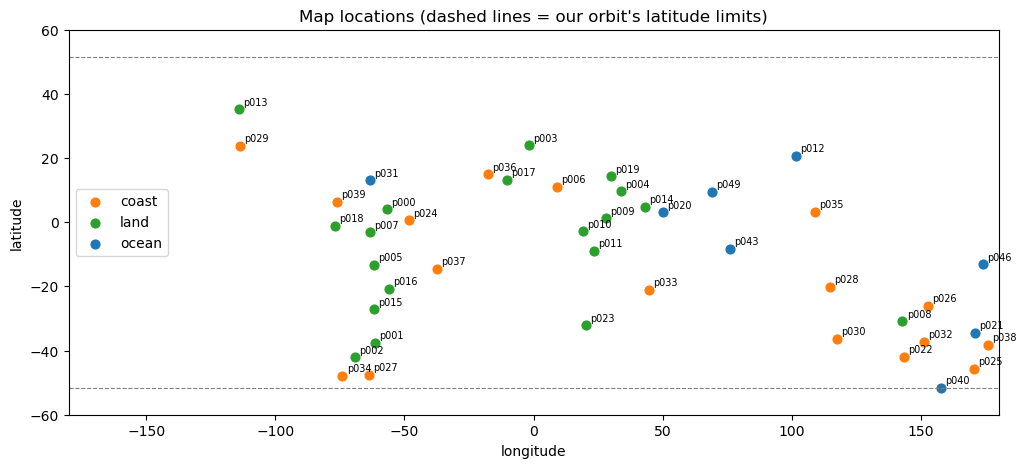

In [34]:
import matplotlib.pyplot as plt
from glob import glob

metas = pd.DataFrame([json.load(open(p)) for p in glob(os.path.join(OUT_DIR, "*", "*.json"))])
maps = metas[metas.season == "jun-aug"].sort_values(["lens", "point_id"])
print(maps.groupby(["lens", "class"]).size().unstack(fill_value=0))
display(maps[["lens", "point_id", "class", "center_lat", "center_lon", "land_share_clear", "cloud_frac"]].round(2))

colors = {"land": "tab:green", "coast": "tab:orange", "island": "tab:purple", "ocean": "tab:blue"}
fig, ax = plt.subplots(figsize=(12, 5))
for cls, g in maps[maps.lens == "FOUND"].groupby("class"):
    ax.scatter(g.center_lon, g.center_lat, s=40, c=colors.get(cls, "gray"), label=cls)
    for r in g.itertuples():
        ax.annotate(r.point_id, (r.center_lon, r.center_lat), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(51.6, ls="--", c="gray", lw=0.8); ax.axhline(-51.6, ls="--", c="gray", lw=0.8)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 60); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title("Map locations (dashed lines = our orbit's latitude limits)"); ax.legend()
plt.show()

In [37]:
import shutil
from glob import glob

EXPORT_DIR = "test_export"
PHOTO_SEASON, MAP_SEASON = "dec-feb", "jun-aug"

metas = pd.DataFrame([json.load(open(p)) for p in glob(os.path.join(OUT_DIR, "*", "*.json"))])
have = metas.groupby(["lens", "point_id"]).season.apply(set)
rows = []
for i, ((lens, pid), seasons) in enumerate(have.items()):
    if not {PHOTO_SEASON, MAP_SEASON} <= seasons:
        continue
    photo, _ = load(lens, pid, PHOTO_SEASON)
    photo = camera_effects(photo, seed=i) if CAMERA_EFFECTS else photo
    photo = cv2.warpPerspective(photo, H_true, (W, H))          # same rotation + shift as the tests
    ref, _ = load(lens, pid, MAP_SEASON)

    for kind, img in [("photos", photo), ("maps", ref)]:
        folder = os.path.join(EXPORT_DIR, lens, kind)
        os.makedirs(folder, exist_ok=True)
        Image.fromarray(img).save(os.path.join(folder, f"{pid}.png"))
    m = metas[(metas.lens == lens) & (metas.point_id == pid) & (metas.season == PHOTO_SEASON)].iloc[0]
    rows.append({"lens": lens, "point_id": pid, "class": m["class"],
                 "center_lat": m.center_lat, "center_lon": m.center_lon,
                 "photo": f"{lens}/photos/{pid}.png", "map": f"{lens}/maps/{pid}.png"})

pd.DataFrame(rows).to_csv(os.path.join(EXPORT_DIR, "index.csv"), index=False)
zip_path = shutil.make_archive(EXPORT_DIR, "zip", EXPORT_DIR)
print(f"Saved {len(rows)} photo/map pairs to '{EXPORT_DIR}/' and zipped to '{zip_path}'")

Saved 85 photo/map pairs to 'test_export/' and zipped to '/Users/prika/ANATOMICAL_DETECTION/test_export.zip'


In [ ]:
import shutil
from glob import glob

RAW_DIR = "raw_export"

metas = pd.DataFrame([json.load(open(p)) for p in glob(os.path.join(OUT_DIR, "*", "*.json"))])
for r in metas.itertuples(index=False):
    folder = os.path.join(RAW_DIR, r.lens, r.season)
    os.makedirs(folder, exist_ok=True)
    src = os.path.join(OUT_DIR, r.lens, f"{r.point_id}_{r.season}_rgb.png")
    shutil.copy(src, os.path.join(folder, f"{r.point_id}.png"))

cols = ["lens", "season", "point_id", "class", "center_lat", "center_lon", "land_share_clear", "cloud_frac"]
metas[[c for c in cols if c in metas.columns]].sort_values(["lens", "season", "point_id"]) \
     .to_csv(os.path.join(RAW_DIR, "index.csv"), index=False)
zip_path = shutil.make_archive(RAW_DIR, "zip", RAW_DIR)
print(f"Copied {len(metas)} original images to '{RAW_DIR}/' and zipped to '{zip_path}'")